In [2]:
import sys
import h5py
print(sys.executable)
print(h5py.__version__)

/opt/conda/bin/python
3.16.0


In [3]:
from pathlib import Path
das_data = Path("/datasets/training/earthquake/share/SISSLE_south30/")
files = sorted(das_data.glob("*.h5"))

print(len(files))
for f in files:
    print(f.name)

noise_file = files[0]  
with h5py.File(noise_file, "r") as f:
    print("keys in file : ")
    for key in f.keys():
        object= f[key]
        print(key)
        print("type: ", type(object))
        if hasattr(object,"shape"):
            print("shape: ", object.shape)
            print("dtype: ", object.dtype)        

16
test_1000.h5
test_1001.h5
test_1010.h5
test_1011.h5
test_1100.h5
test_1101.h5
test_1110.h5
test_1111.h5
train_1000.h5
train_1001.h5
train_1010.h5
train_1011.h5
train_1100.h5
train_1101.h5
train_1110.h5
train_1111.h5
keys in file : 
meta
type:  <class 'h5py._hl.dataset.Dataset'>
shape:  (512,)
dtype:  [('path', 'O'), ('x0', '<i4'), ('t0', '<i4')]
patches
type:  <class 'h5py._hl.dataset.Dataset'>
shape:  (512, 256, 512)
dtype:  float32


In [4]:
with h5py.File(noise_file, "r") as f:
    meta = f["meta"]
    print("meta shape: ", meta.shape)
    print("meta dtype: ", meta.dtype)
    for i in range(5):
        print(i,meta[i])

meta shape:  (512,)
meta dtype:  [('path', 'O'), ('x0', '<i4'), ('t0', '<i4')]
0 (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20231028/south30_100Hz_UTC_20231028_201001.131.h5', 400, 2129)
1 (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20231028/south30_100Hz_UTC_20231028_194201.131.h5', 5097, 1035)
2 (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20231028/south30_100Hz_UTC_20231028_182601.131.h5', 3209, 4845)
3 (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20231028/south30_100Hz_UTC_20231028_164601.131.h5', 3809, 753)
4 (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20231028/south30_100Hz_UTC_20231028_143401.131.h5', 2843, 1701)


In [5]:
for f in files:
    with h5py.File(f, "r") as file:
        print(f.name)
        print("patches shape: ", file["patches"].shape)
        print("meta shape: ", file["meta"].shape)

test_1000.h5
patches shape:  (512, 256, 512)
meta shape:  (512,)
test_1001.h5
patches shape:  (512, 256, 512)
meta shape:  (512,)
test_1010.h5
patches shape:  (512, 256, 512)
meta shape:  (512,)
test_1011.h5
patches shape:  (128, 256, 512)
meta shape:  (128,)
test_1100.h5
patches shape:  (512, 256, 512)
meta shape:  (512,)
test_1101.h5
patches shape:  (128, 256, 512)
meta shape:  (128,)
test_1110.h5
patches shape:  (128, 256, 512)
meta shape:  (128,)
test_1111.h5
patches shape:  (128, 256, 512)
meta shape:  (128,)
train_1000.h5
patches shape:  (16384, 256, 512)
meta shape:  (16384,)
train_1001.h5
patches shape:  (16384, 256, 512)
meta shape:  (16384,)
train_1010.h5
patches shape:  (16384, 256, 512)
meta shape:  (16384,)
train_1011.h5
patches shape:  (4096, 256, 512)
meta shape:  (4096,)
train_1100.h5
patches shape:  (16384, 256, 512)
meta shape:  (16384,)
train_1101.h5
patches shape:  (4096, 256, 512)
meta shape:  (4096,)
train_1110.h5
patches shape:  (4096, 256, 512)
meta shape:  (409

In [15]:
originals = set()
for f in files:
    with h5py.File(f, "r") as f:
        for row in f ["meta"]:
            originals.add(row[0])
print("number of unique original paths: ", len(originals))            

number of unique original paths:  3688


In [7]:
train_originals = set()
train_files = sorted(das_data.glob("train_*.h5"))
for f in train_files:
    with h5py.File(f, "r") as f:
        for row in f ["meta"]:
            train_originals.add(row[0])
print("number of unique original paths in training data: ", len(train_originals))

number of unique original paths in training data:  3303


In [17]:
test_originals = set()
test_files = sorted(das_data.glob("test_*.h5"))
for f in test_files:
    with h5py.File(f, "r") as f:
        for row in f ["meta"]:
            test_originals.add(row[0])
print("number of unique original paths in training data: ", len(test_originals))

number of unique original paths in training data:  385


In [9]:
height = 256
width = 512
positions={}
t0_set={}
x0_set={}
for f in train_files:
    with h5py.File(f,"r") as f :
        for path, x0, t0 in f["meta"]:
            pos=(path, x0, t0)
            positions[pos]= positions.get(pos, 0) + 1

            t=(path, x0)
            if t not in t0_set:
                t0_set[t]=[]
            t0_set[t].append(t0)

            x=(path,t0)
            if x not in x0_set:
                x0_set[x]=[]
            x0_set[x].append(x0)    

In [10]:
repeated_unique = 0
repeated_extra = 0
for p in positions.values():
    if p>1:
        repeated_unique+=1
        repeated_extra+= p-1
print("repeated unique(path,x0,t0) positions: ", repeated_unique)
print("duplicate patches: ", repeated_extra)        

repeated unique(path,x0,t0) positions:  2
duplicate patches:  3


In [13]:
t_steps = {}
time_overlap =0
time_direct = 0
time_gap = 0
for t0_list in t0_set.values():
    t0_list=sorted(t0_list)
    for i in range(len(t0_list)-1):
        t_step= t0_list[i+1]-t0_list[i]
        if t_step not in t_steps:
            t_steps[t_step] = 1
        else:
            t_steps[t_step] += 1

        if t_step < width:
            time_overlap += 1 
        elif t_step == width:
            time_direct += 1
        else: time_gap += 1    
        

print("common t steps:")
print(t_steps)
print("time overlaps t < 512 : ", time_overlap)
print("time direct t = 512 : ", time_direct)
print("time gaps t > 512 : ", time_gap)

common t steps:
{1303: 1, 4589: 1, 3782: 1, 2656: 1, 1488: 1, 989: 1, 2937: 1, 114: 1, 5034: 1, 3459: 1, 883: 1, 768: 1, 97: 3, 215: 2, 4576: 1, 4664: 1, 1771: 1, 1495: 1, 525: 1, 2724: 1, 2609: 1, 3605: 1, 1871: 1, 3634: 1, 1912: 1, 2528: 1, 198: 4, 899: 1, 1403: 1, 3385: 1, 1138: 1, 4260: 1, 2989: 1, 294: 3, 1043: 2, 262: 2, 23: 4, 679: 1, 164: 1, 852: 1, 130: 3, 77: 4, 136: 3, 331: 2, 526: 2, 192: 5, 40: 4, 292: 1, 151: 4, 549: 1, 160: 1, 302: 1, 683: 1, 233: 2, 740: 2, 278: 2, 100: 6, 182: 4, 202: 2, 167: 2, 94: 3, 14: 5, 436: 2, 89: 3, 2946: 1, 338: 3, 448: 1, 32: 2, 418: 2, 74: 2, 103: 2, 18: 6, 58: 2, 68: 2, 734: 1, 365: 2, 777: 1, 1052: 1, 371: 1, 2718: 1, 93: 2, 123: 6, 191: 2, 272: 3, 34: 3, 56: 7, 66: 6, 73: 4, 241: 4, 57: 1, 106: 3, 273: 3, 633: 3, 44: 5, 808: 1, 140: 3, 20: 3, 851: 1, 134: 2, 127: 4, 756: 1, 82: 2, 236: 2, 337: 3, 274: 4, 98: 6, 266: 1, 59: 4, 467: 2, 308: 1, 61: 4, 1765: 1, 382: 3, 1105: 1, 71: 3, 19: 3, 258: 1, 41: 8, 13: 2, 1513: 1, 408: 3, 87: 1, 575: 

In [14]:
channel_steps = {}
channel_overlap =0
channel_direct = 0
channel_gap = 0
for x0_list in x0_set.values():
    x0_list=sorted(x0_list)
    for i in range(len(x0_list)-1):
        x_step= x0_list[i+1]-x0_list[i]
        if x_step not in channel_steps:
            channel_steps[x_step] = 1
        else:
            channel_steps[x_step] += 1

        if x_step < height:
            channel_overlap += 1 
        elif x_step == height:
            channel_direct += 1
        else: channel_gap += 1    
       

print("common x steps:")
print(channel_steps)
print("channel overlaps x < 256 : ", channel_overlap)
print("channel direct x = 256 : ", channel_direct)
print("channel gaps x > 256 : ", channel_gap)

common x steps:
{3195: 2, 3311: 1, 3528: 1, 4092: 1, 3116: 2, 2317: 4, 420: 6, 404: 3, 6323: 1, 3687: 2, 933: 2, 438: 2, 2319: 2, 1399: 2, 1114: 1, 860: 3, 2579: 1, 4299: 1, 4045: 1, 1440: 4, 26: 4, 2433: 2, 3838: 2, 710: 4, 2599: 2, 1529: 2, 3545: 1, 761: 3, 2062: 1, 1627: 2, 2341: 2, 628: 1, 162: 2, 4147: 1, 1782: 3, 5660: 1, 1395: 3, 410: 3, 1279: 1, 2520: 2, 2413: 1, 5168: 1, 2726: 2, 658: 1, 2709: 1, 301: 2, 3088: 2, 1108: 2, 4537: 1, 659: 4, 6166: 1, 67: 2, 3112: 1, 2052: 2, 4339: 2, 683: 2, 947: 4, 3827: 2, 505: 3, 401: 3, 718: 1, 2316: 1, 6: 5, 1193: 3, 4120: 1, 1528: 1, 1022: 2, 1294: 2, 865: 3, 1216: 1, 757: 2, 2532: 3, 1045: 3, 2276: 1, 339: 2, 152: 3, 260: 1, 215: 2, 954: 1, 2233: 2, 261: 5, 1943: 1, 441: 4, 322: 2, 309: 2, 1967: 1, 312: 2, 807: 2, 6033: 1, 2271: 2, 406: 2, 666: 2, 3386: 1, 104: 3, 624: 2, 2015: 1, 479: 2, 127: 3, 1930: 3, 3150: 1, 443: 4, 293: 3, 1795: 3, 1469: 2, 1750: 1, 2693: 4, 3520: 2, 265: 3, 449: 4, 60: 8, 10: 6, 29: 2, 61: 7, 264: 3, 222: 6, 134: 3

patch index:  0
min/max: -279.33545 307.1931
mean/std: 1.5409291 48.07544
meta:  (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20230226/south30_100Hz_UTC_20230226_173800.122.h5', 389, 3642)



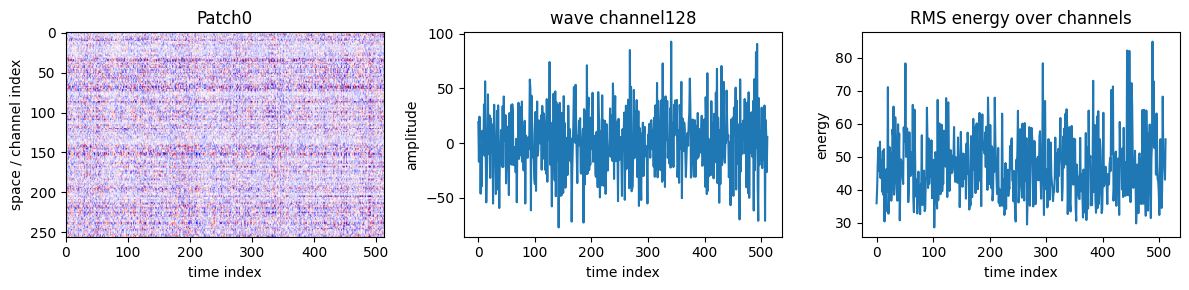

patch index:  1
min/max: -3367.19 2308.167
mean/std: 0.82356924 113.92224
meta:  (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20230226/south30_100Hz_UTC_20230226_190500.122.h5', 5823, 4938)



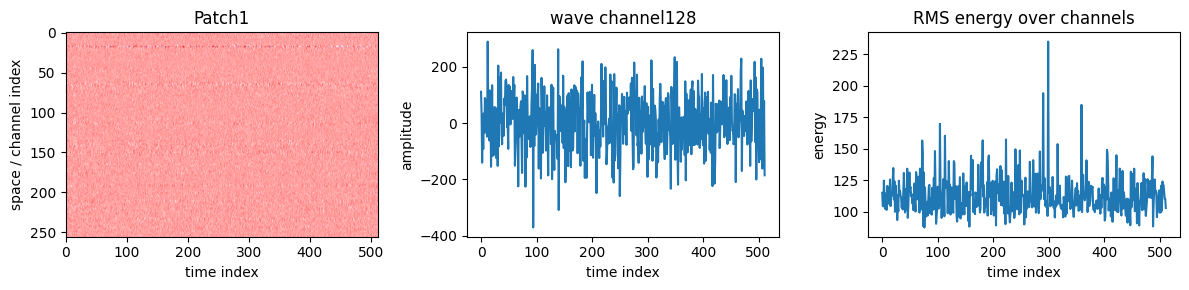

patch index:  2
min/max: -339.31125 406.71088
mean/std: -2.3509653 57.039486
meta:  (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20230226/south30_100Hz_UTC_20230226_203800.122.h5', 3122, 1498)



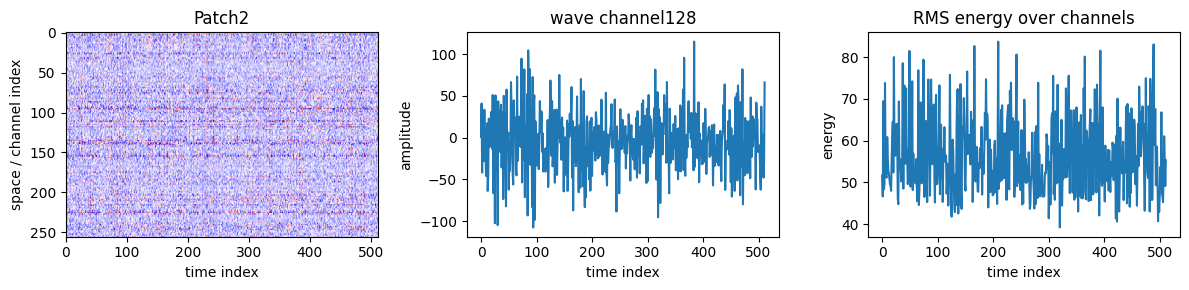

patch index:  50
min/max: -386.98648 409.61102
mean/std: 1.9366955 56.07334
meta:  (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20230226/south30_100Hz_UTC_20230226_144700.122.h5', 3047, 5219)



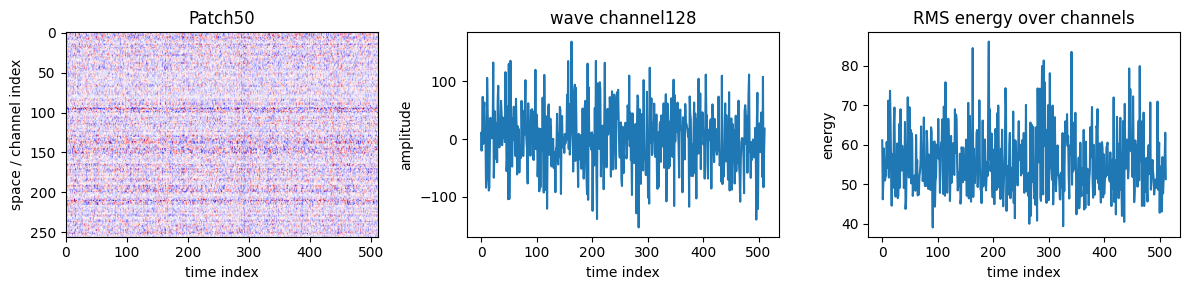

patch index:  200
min/max: -1012.35406 910.6289
mean/std: -0.3390099 75.41221
meta:  (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20230223/south30_100Hz_UTC_20230223_110600.135.h5', 4331, 5306)



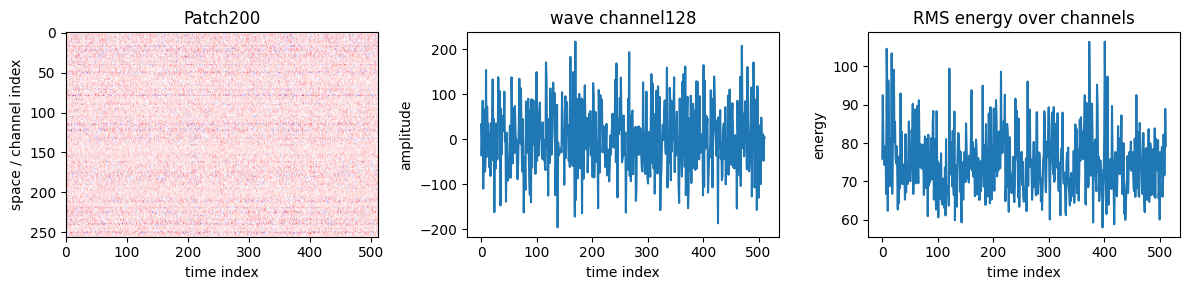

patch index:  511
min/max: -792.8164 543.76764
mean/std: 3.3197365 73.14766
meta:  (b'/share/CACHEDEV1_DATA/DAS/SISSLE_100Hz/south30/20230226/south30_100Hz_UTC_20230226_080200.122.h5', 3672, 4967)



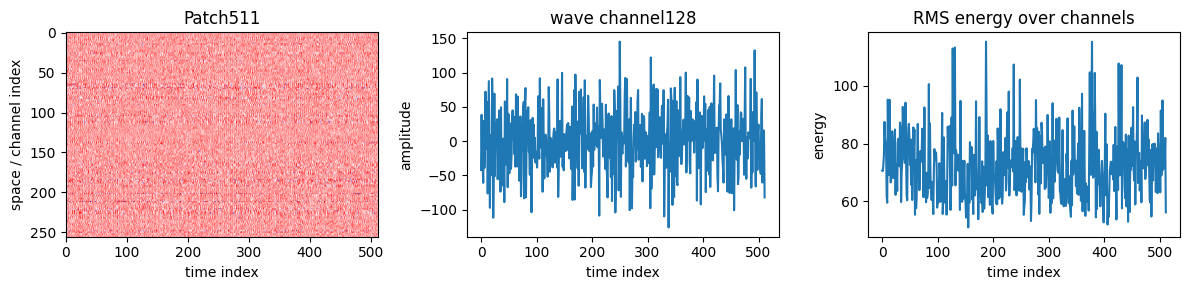

In [25]:
import matplotlib.pyplot as plt
import numpy as np

file = das_data/"train_1000.h5"
patch_indexes= [0, 1, 2, 50, 200, 511]
channel_index=128
with h5py.File(file, "r") as f :
    for i in patch_indexes:
        patch = f["patches"][i]
        meta = f["meta"][i]
        channel_wave= patch[channel_index]
        energy_wave = np.sqrt(np.mean(patch**2, axis = 0))

        print("patch index: ", i)
        print("min/max:", patch.min(), patch.max())
        print("mean/std:", patch.mean(), patch.std())
        print("meta: ", meta)
        print()

        fig,axes = plt.subplots(1,3,figsize=(12,3))
        
        axes[0].imshow(patch, aspect="auto", cmap="seismic")
        axes[0].set_title(f"Patch{i}")
        axes[0].set_xlabel("time index")
        axes[0].set_ylabel("space / channel index")

        axes[1].plot(channel_wave)
        axes[1].set_title(f"wave channel{channel_index}")
        axes[1].set_xlabel("time index")
        axes[1].set_ylabel("amplitude")

        axes[2].plot(energy_wave)
        axes[2].set_title(f"RMS energy over channels")
        axes[2].set_xlabel("time index")
        axes[2].set_ylabel("energy")
        plt.tight_layout()
        plt.show()

In [ ]:
from ipywidgets import interact, Dropdown, IntSlider

def show_patch(filename, patch_index):
    file_path = das_data / filename
    
    with h5py.File(file_path, "r") as f:
        patches = f["patches"]
        meta = f["meta"][patch_index]
        patch = patches[patch_index]
        total = patches.shape[0]
    
    print("File:", filename)
    print("Patch index:", patch_index, "/", total - 1)
    print("Patch shape:", patch.shape)
    print("Min/max:", patch.min(), patch.max())
    print("Meta:", meta)
    
    plt.figure(figsize=(10, 5))
    plt.imshow(patch, aspect="auto", cmap="seismic")
    plt.colorbar(label="amplitude")
    plt.title(f"{filename} - patch {patch_index}")
    plt.xlabel("time index")
    plt.ylabel("space/channel index")
    plt.show()

interact(
    show_patch,
    filename=Dropdown(options=files, value="train_1111.h5", description="File"),
    patch_index=IntSlider(min=0, max=16383, step=1, value=0, description="Patch"),
)

interactive(children=(Dropdown(description='File', index=15, options=('test_1000.h5', 'test_1001.h5', 'test_10…

<function __main__.show_patch(filename, patch_index)>